In [1]:
import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("GPU Memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")
else:
    print("GPU is not enabled")

PyTorch Version: 2.14.1+cu130
CUDA Available: True
GPU Name: Tesla T4
GPU Memory: 14.56 GB


In [2]:
import torch
import torch.nn as nn
import time
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
class InferenceModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.network(x)

model = InferenceModel()
model.eval()

print("Model created successfully")

Model created successfully


In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

print("Model Device:", device)

Model Device: cuda


In [5]:
batch_size = 4096

input_data = torch.randn(batch_size, 1024)

print("Input Shape:", input_data.shape)
print("Input Device:", input_data.device)

Input Shape: torch.Size([4096, 1024])
Input Device: cpu


In [6]:
input_gpu = input_data.to(device)

with torch.no_grad():
    output = model(input_gpu)

print("Inference completed successfully")
print("Output Shape:", output.shape)
print("Output Device:", output.device)

Inference completed successfully
Output Shape: torch.Size([4096, 10])
Output Device: cuda:0


In [7]:
# Warm-up
for _ in range(10):
    with torch.no_grad():
        model(input_gpu)

torch.cuda.synchronize()

# Measure inference time
start = time.time()

for _ in range(100):
    with torch.no_grad():
        model(input_gpu)

torch.cuda.synchronize()

end = time.time()

avg_time = (end - start) / 100

print("Average Inference Time:", avg_time * 1000, "ms")
print("Throughput:", batch_size / avg_time, "samples/second")

Average Inference Time: 2.329998016357422 ms
Throughput: 1757941.4107843058 samples/second


In [8]:
# Measure CPU to GPU transfer
torch.cuda.synchronize()
start = time.time()

for _ in range(100):
    x = input_data.to(device)

torch.cuda.synchronize()
transfer_time = (time.time() - start) / 100

# Measure GPU computation
start = time.time()

for _ in range(100):
    with torch.no_grad():
        output = model(input_gpu)

torch.cuda.synchronize()
compute_time = (time.time() - start) / 100

# Measure GPU to CPU transfer
start = time.time()

for _ in range(100):
    result = output.cpu()

torch.cuda.synchronize()
output_time = (time.time() - start) / 100

print("CPU to GPU Transfer:", transfer_time * 1000, "ms")
print("GPU Computation:", compute_time * 1000, "ms")
print("GPU to CPU Transfer:", output_time * 1000, "ms")

CPU to GPU Transfer: 3.356146812438965 ms
GPU Computation: 2.149524688720703 ms
GPU to CPU Transfer: 0.06735801696777344 ms


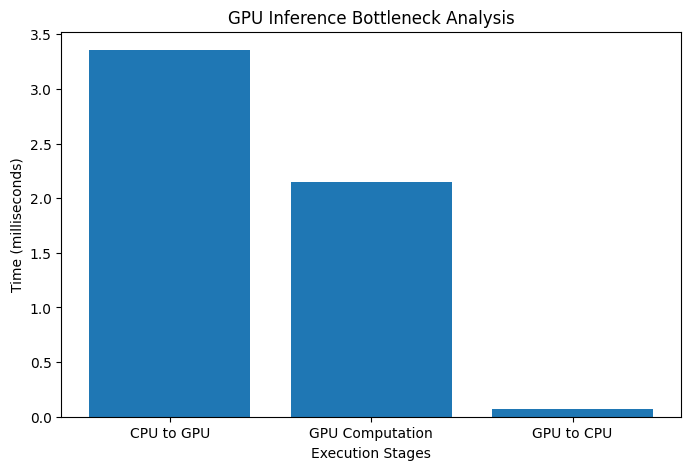

In [9]:
stages = [
    "CPU to GPU",
    "GPU Computation",
    "GPU to CPU"
]

times = [
    transfer_time * 1000,
    compute_time * 1000,
    output_time * 1000
]

plt.figure(figsize=(8, 5))
plt.bar(stages, times)
plt.ylabel("Time (milliseconds)")
plt.xlabel("Execution Stages")
plt.title("GPU Inference Bottleneck Analysis")
plt.show()

In [10]:
print("Allocated GPU Memory:",
      round(torch.cuda.memory_allocated() / 1024**2, 2), "MB")

print("Reserved GPU Memory:",
      round(torch.cuda.memory_reserved() / 1024**2, 2), "MB")

print("Maximum GPU Memory:",
      round(torch.cuda.max_memory_allocated() / 1024**2, 2), "MB")

Allocated GPU Memory: 42.79 MB
Reserved GPU Memory: 78.0 MB
Maximum GPU Memory: 58.79 MB


In [11]:
!nvidia-smi

Thu Nov 26 03:11:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   75C    P0             35W /   70W |     209MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----